## 다음 영화 리뷰 데이터 분석
1. 데이터 로딩
2. 텍스트 전처리
3. 빈도수 계산
4. 시각화

In [5]:
# 데이터 로딩
import pandas as pd
datafile = 'data/daum_movie_review.csv'
df = pd.read_csv(datafile)
df.head()

# 감성분석을 할경우 review, rating 컬럼만, 영화에 대한 리뷰가 필요할 경우 title컬럼까지 추가해서

,review,rating,date,title
0,돈 들인건 티가 나지만 보는 내내 하품만,1,2018.10.29,인피니티 워
1,몰입할수밖에 없다. 어렵게 생각할 필요없다. 내가 전투에 참여한듯 손에 땀이남.,10,2018.10.26,인피니티 워
2,이전 작품에 비해 더 화려하고 스케일도 커졌지만.... 전국 맛집의 음식들을 한데 ...,8,2018.10.24,인피니티 워
3,이 정도면 볼만하다고 할 수 있음!,8,2018.10.22,인피니티 워
4,재미있다,10,2018.10.20,인피니티 워


In [9]:
df.tail()

,review,rating,date,title
14720,어른들을 위한 동화 정말 오랜만에 좋은 애니를 보았습니다 가족의 소중...,10,2018.01.12,코코
14721,디즈니는 못해도 본전은 한다.,7,2018.01.12,코코
14722,가족을 위한 영화... 괜찮은 영화.~~~,8,2018.01.12,코코
14723,간만에 제대로 잘짜여진 각본의 영화를 봤네 여운이 아직도 남아~어른을 위한 애니~,10,2018.01.12,코코
14724,한국개봉을 눈빠지게 기다린 보람이있다 깨우치는게 많은 영화,10,2018.01.12,코코


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14725 entries, 0 to 14724
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  14725 non-null  str  
 1   rating  14725 non-null  int64
 2   date    14725 non-null  str  
 3   title   14725 non-null  str  
dtypes: int64(1), str(3)
memory usage: 460.3 KB


In [ ]:
# 품사 태깅-> 토큰화, 불용어 제거
from konlpy.tag import Okt

tagger = Okt()
reviews = list(df.review) #자료구조가 시리즈가 기본으로 되어있어서 list로 캐스팅

pos_list = [tagger.pos(review) for review in reviews]
# for review in reviews:
#     tokens = tagger.pos(review)
#     pos_list.append(tokens)
len(pos_list)

14725

In [50]:
pos_list[:1]

[[('돈', 'Noun'),
  ('들인건', 'Verb'),
  ('티', 'Noun'),
  ('가', 'Josa'),
  ('나', 'Noun'),
  ('지만', 'Josa'),
  ('보는', 'Verb'),
  ('내내', 'Noun'),
  ('하품', 'Noun'),
  ('만', 'Josa')]]

In [60]:
# 불용어 제거
# 관심있는 3개의 품사의 리스트만 만들어 추출
# 불용어 제거 -> 필요한 품사의 단어만 추출

my_tags = ['Noun', 'Verb', 'Adjective']
my_stopwords = ['영화', '것', '이', '더', '그']

# 빈도수를 추출하기 위해 리뷰별로 리스트로 관리할 필요가 없어짐
# 한 리스트 안에 필요만 품사의 단어만 리스트에 넣는다
result_list1 = []
for review in pos_list:
    for word, tag in review:
        if tag in my_tags and word not in my_stopwords:
            result_list1.append(word)
result_list1[:10]

# 나중에 고빈도수 단어를 봤을때 불용어가 있다면 불용어 사전을 만들어 제거하면 된다

['돈', '들인건', '티', '나', '보는', '내내', '하품', '몰입', '할수밖에', '없다']

In [62]:
pos = []
for review in pos_list:
    pos += review
result_list2 = [word for word, tag in pos if tag in my_tags and word not in my_stopwords]
result_list2[:10]

['돈', '들인건', '티', '나', '보는', '내내', '하품', '몰입', '할수밖에', '없다']

In [61]:
# 빈도수 계산 -> Counter 객체를 생성하여 사용
from collections import Counter
counter = Counter(result_list1)
count_list = counter.most_common(20) # 빈도수 상위 20위까지의 단어와 카운트 출력

In [37]:
# matplotlib의 
from matplotlib import font_manager, rc

font_path = 'C:/Windows/Fonts/malgun.ttf'
font_name = font_manager.FontProperties(fname = font_path).get_name()
rc('font', family=font_name)

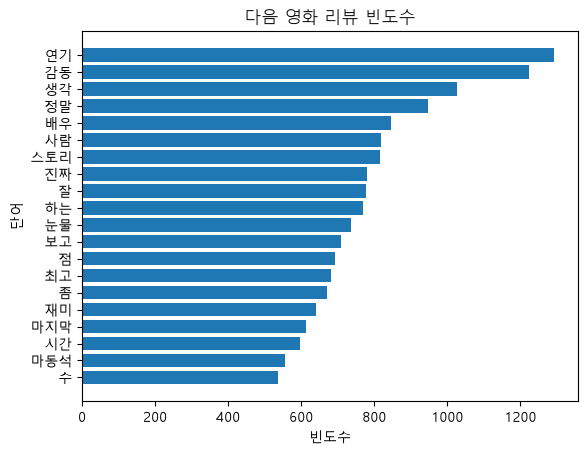

In [ ]:
# 시각화 - 수평 막대 그래프
import matplotlib.pyplot as plt

# (1) 데이터 준비
x = [word for word, count in count_list]
y = [count for word, count in count_list]

# x = []
# y = []
# for word, count in count_list:
#     x.append(word)
#     y.append(count)

# (2) 막대 그래프 생성
plt.barh(x[::-1], y[::-1])

# (3) 필요 정보 추가
plt.title('다음 영화 리뷰 빈도수')
plt.xlabel('빈도수')
plt.ylabel('단어')

# (4) 출력
# plt.show()
plt.savefig('result/daum_movie_reveiw_graph.jpg')


In [3]:
# 대한민국 헌법의 wordcloud 생성하기
from konlpy.corpus import kolaw
input_filename = 'constitution.txt'
const_doc = kolaw.open(input_filename).read()
len(const_doc), type(const_doc)

(18884, str)

In [4]:
const_doc[:100]

'대한민국헌법\n\n유구한 역사와 전통에 빛나는 우리 대한국민은 3·1운동으로 건립된 대한민국임시정부의 법통과 불의에 항거한 4·19민주이념을 계승하고, 조국의 민주개혁과 평화적 통일의'

In [6]:
# wordcloud 설치
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [11]:
from wordcloud import WordCloud

font_path = 'C:/Windows/Fonts/malgun.ttf'

# wordcloud 클래스의 객체 생성
wc = WordCloud(font_path)

In [12]:
# wordcloud 생성 from 텍스트
wc.generate(const_doc)

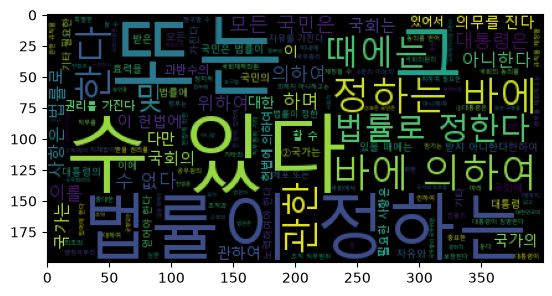

In [14]:
# matplotlib.pyplot으로 연동하여 시각화
import matplotlib.pyplot as plt
plt.imshow(wc)

# pyplot의 객체를 화면으로 출력
plt.show()

In [18]:
# 헌법 -> 전처리 -> 빈도수 객체 (Counter)
# 전처리 : 토큰화, 정제, 정규화 -> 품사태깅, 불용어 제거

# 품사태깅
from konlpy.tag import Okt
tagger = Okt().pos

tokens = tagger(const_doc)
tokens[:10]

[('대한민국', 'Noun'),
 ('헌법', 'Noun'),
 ('\n\n', 'Foreign'),
 ('유구', 'Noun'),
 ('한', 'Josa'),
 ('역사', 'Noun'),
 ('와', 'Josa'),
 ('전통', 'Noun'),
 ('에', 'Josa'),
 ('빛나는', 'Verb')]

In [48]:
# 불용어 제거 : 원하는 품사 정의, 삭제할 단어 사전 정의
my_tags = ['Noun']
my_stopwords = ['제', '정', '수', '때', '법률', '관', '항']

result_list = [word for word, tag in tokens if tag in my_tags and word not in my_stopwords]
result_list[:10]

['대한민국', '헌법', '유구', '역사', '전통', '우리', '국민', '운동', '건립', '대한민국']

In [49]:
# 빈도수 계산 : Counter 클래스
from collections import Counter
counter = Counter(result_list)

In [50]:
from wordcloud import WordCloud

font_path = 'C:/Windows/Fonts/malgun.ttf'

# wordcloud 클래스의 객체 생성
# API : https://amueller.github.io/word_cloud/generated/wordcloud.WordCloud.html#wordcloud.WordCloud
wc = WordCloud(
    font_path
    ,background_color='ivory'
    ,width = 800        #넓이
    ,height = 400       #높이
    ,max_words = 100    #출력할 단어 개수
)

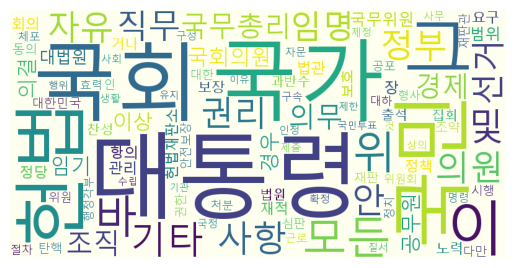

In [51]:
# wordcloud 적용
wc.generate_from_frequencies(counter)
plt.imshow(wc)
plt.axis('off')
plt.show()

In [52]:
# wordcloud 이미지를 파일로 저장
wc.to_file('result/const_doc_wordcloud.jpg')